# Visite guidée : market making FX, de la formule au Sharpe de marché

Chaque bloc suit le même fil : **intuition → formule → attente → code → lecture**.
L'*attente* est écrite AVANT d'exécuter le code ; la *lecture* dit si le résultat la confirme.
Unités : prix en pips, temps en secondes, inventaire en lots (1 lot = 1 M EUR, donc 1 pip x 1 lot = 100 USD).
Le TEST (2023+) n'est jamais lu : `charger_annee` le refuse.

In [1]:
import sys, warnings
from dataclasses import replace
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent))          # le notebook vit dans notebooks/
from mm.calibration import Hypotheses, sigma_par_heure, sigma_session
from mm.modeles import (jeu_strategies_base, strategie_placebo, profondeurs_as, profondeurs_glft, profondeurs_naif,
                        prix_reservation, spread_total_as)
from mm.simulateur import Marche, simuler_session, simuler_trajectoire, O_PNL
from mm.monte_carlo import monte_carlo, resumer, balayage_1d, sharpe_annualise
from mm.donnees import ANNEES_VAL
from mm.rejeu_reel import construire_jours, rejouer, resume_markout, MODELES_FILL
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

## 1. Le problème du market maker

**Intuition.** Un market maker affiche un prix d'achat (bid) et un prix de vente (ask). Chaque fois qu'un client
traite, il encaisse un petit écart (la *capture de spread*). Mais il se retrouve avec une position (l'*inventaire*) :
si le prix part contre elle, la perte dépasse vite les petits gains. Tout le métier tient dans cet arbitrage.

**Formule.** Entre deux instants, la richesse varie de deux façons :
$\Delta W = \underbrace{(\text{mid} - \text{prix d'exécution})\cdot\text{sens}}_{\text{capture de spread}} + \underbrace{q\,\Delta S}_{\text{variation de valeur de l'inventaire}}$,
puis on paie la liquidation de l'inventaire résiduel et les frais.

**Attente.** Si le prix ne bouge pas ($\sigma=0$) et si le flux n'est pas informé ($p=0$), le PnL doit être *exactement*
(demi-spread posé) x (nombre d'exécutions), moins la liquidation finale.

In [2]:
h = Hypotheses()
marche_test = Marche(sigma=0.0, A=h.A, k=h.k, p_adverse=0.0, alpha=h.alpha, demi_spread_liq=h.demi_spread_marche,
                     frais=0.0, dt=1.0, duree=3600.0)
naif = jeu_strategies_base(0.33, h.A, h.k, h.Q, 3600.0)[0]
r = simuler_session(naif, marche_test, graine=1, indice=0)
attendu = naif.demi_naif * r["n_executions"] - marche_test.demi_spread_liq * abs(r["inventaire_final"])
print(f"exécutions : {r['n_executions']:.0f}   PnL simulé : {r['pnl']:.6f}   PnL attendu : {attendu:.6f}")
print(f"inventaire (doit être 0 sans mouvement de prix) : {r['inventaire']}")

exécutions : 253   PnL simulé : 40.866667   PnL attendu : 40.866667
inventaire (doit être 0 sans mouvement de prix) : 0.0


**Lecture.** Les deux PnL sont identiques à la précision machine et la composante « inventaire » est nulle : le moteur
de comptabilité est cohérent. C'est la première brique de confiance ; elle est aussi vérifiée à 1e-9 dans `tests/`.

## 2. Avellaneda-Stoikov : le prix de réservation

**Intuition.** Si je suis long de 5 lots, je veux vendre plutôt qu'acheter. Je décale donc mes deux cotes vers le bas :
mon « vrai » prix de référence n'est plus le mid $s$ mais un *prix de réservation* $r$ plus bas.

**Formule.** $r = s - q\,\gamma\,\sigma^2\,(T-t)$ et spread total $= \gamma\sigma^2(T-t) + \frac{2}{\gamma}\ln(1+\gamma/k)$.
Le décalage croît avec l'inventaire $q$, l'aversion au risque $\gamma$, la variance $\sigma^2$ et le temps restant.

**Attente.** Pour $q=0$ : $r=s$ et cotes symétriques. Pour $q>0$ : bid plus loin du mid, ask plus proche.
Le spread total augmente avec $\gamma$ et $\sigma$.

In [3]:
sigma_h = sigma_par_heure()            # TRAIN 2010-2018 uniquement
sigma = sigma_session(sigma_h)
strategies = jeu_strategies_base(sigma, h.A, h.k, h.Q, 9 * 3600.0)
naif, as_, plafonne, glft = strategies
print(f"sigma de la session de Londres (TRAIN) : {sigma:.3f} pip/sqrt(s)   gamma_AS = {as_.gamma:.2e}   gamma_GLFT = {glft.gamma:.2e}")
tau = 4.5 * 3600  # mi-session
for q in (-10, -5, 0, 5, 10):
    db, da = profondeurs_as(q, as_.gamma, sigma, h.k, tau)
    print(f"q={q:+3d}  r-s={prix_reservation(0.0, q, as_.gamma, sigma, tau):+.3f} pip   profondeur bid={db:.3f}  ask={da:.3f}")
for g in (as_.gamma / 4, as_.gamma, as_.gamma * 4):
    print(f"gamma={g:.1e}  spread total={spread_total_as(g, sigma, h.k, tau):.3f} pip")

sigma de la session de Londres (TRAIN) : 0.330 pip/sqrt(s)   gamma_AS = 9.46e-06   gamma_GLFT = 1.13e-03
q=-10  r-s=+0.167 pip   profondeur bid=0.008  ask=0.342
q= -5  r-s=+0.083 pip   profondeur bid=0.092  ask=0.258
q= +0  r-s=+0.000 pip   profondeur bid=0.175  ask=0.175
q= +5  r-s=-0.083 pip   profondeur bid=0.258  ask=0.092
q=+10  r-s=-0.167 pip   profondeur bid=0.342  ask=0.008
gamma=2.4e-06  spread total=0.337 pip
gamma=9.5e-06  spread total=0.350 pip
gamma=3.8e-05  spread total=0.400 pip


**Lecture.** Pour $q=0$ la réservation égale le mid ; plus on est long, plus le bid s'éloigne et plus l'ask se rapproche
(jusqu'à coter au mid : la profondeur est plancher à 0, car l'intensité $\lambda(\delta)$ n'est valable que pour $\delta\ge0$).
Le spread total grandit bien avec $\gamma$.

## 3. Les quatre façons de gérer l'inventaire

**Intuition.** Naïf : aucune réaction. AS : réaction proportionnelle à $q$ et au temps restant. AS plafonné : même chose
mais le décalage est borné. GLFT : version stationnaire (horizon long) avec une pente constante en $q$.
Toutes ont le même critère d'agressivité (décalage de $1/k$ à $Q/2$ lots) : on compare des logiques, pas des $\gamma$.

**Attente.** Des droites en $q$ (AS, GLFT), une droite plate (naïf), une droite qui plafonne (AS plafonné).

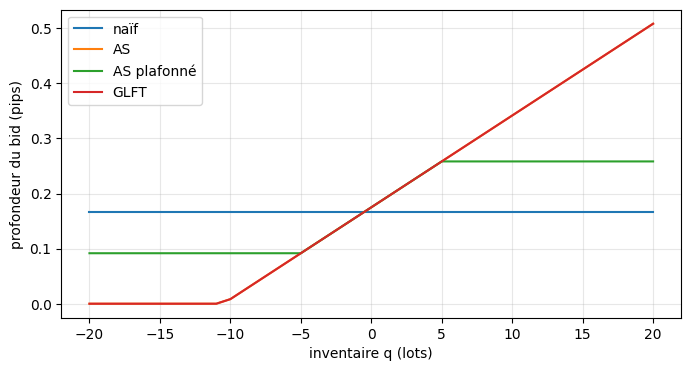

In [4]:
from mm.modeles import profondeurs_as_plafonne
qs = np.arange(-20, 21)
fig, ax = plt.subplots(figsize=(8, 4))
for nom, f in [("naïf", lambda q: profondeurs_naif(naif.demi_naif)),
               ("AS", lambda q: profondeurs_as(q, as_.gamma, sigma, h.k, tau)),
               ("AS plafonné", lambda q: profondeurs_as_plafonne(q, as_.gamma, sigma, h.k, tau, plafonne.cap)),
               ("GLFT", lambda q: profondeurs_glft(q, glft.gamma, sigma, h.A, h.k))]:
    ax.plot(qs, [max(f(q)[0], 0) for q in qs], label=nom)
ax.set_xlabel("inventaire q (lots)"); ax.set_ylabel("profondeur du bid (pips)"); ax.legend(); plt.show()

**Lecture.** Les trois modèles à inventaire montent avec $q$ ; le plafond aplatit AS ; le naïf ne bouge pas.
La profondeur du bid s'annule pour les inventaires négatifs forts : on rachète au mid pour revenir à zéro.

## 4. Une session simulée

**Intuition.** Le mid suit un brownien arithmétique ; à chaque pas, une exécution arrive côté bid ou ask avec la probabilité
$1-e^{-\lambda\,dt}$, $\lambda=A\,e^{-k\delta}$ : plus je cote loin, moins j'ai de clients.

**Attente.** L'inventaire du naïf dérive comme une marche aléatoire jusqu'à la borne $Q$ ; celui d'AS et de GLFT reste près de 0.

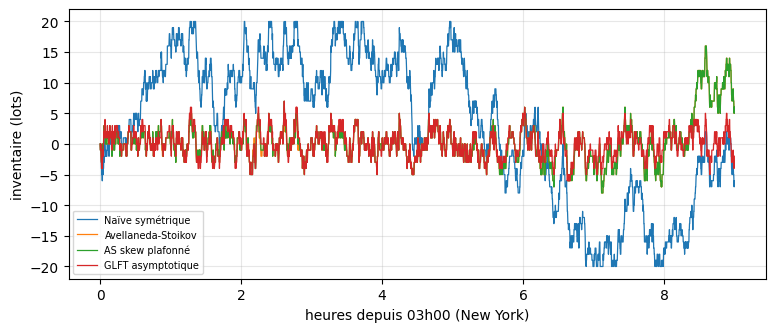

{'Naïve symétrique': 20, 'Avellaneda-Stoikov': 16, 'AS skew plafonné': 16, 'GLFT asymptotique': 7}


In [5]:
marche = Marche(sigma=sigma, A=h.A, k=h.k, p_adverse=h.p_adverse, alpha=h.alpha,
                demi_spread_liq=h.demi_spread_marche, frais=h.frais, dt=0.1)
traj = [simuler_trajectoire(s, marche, graine=20260713, indice=0) for s in strategies]
fig, ax = plt.subplots(figsize=(9, 3.5))
for s, t in zip(strategies, traj):
    ax.plot(t["temps"][::100] / 3600, t["inventaire"][::100], label=s.nom, lw=0.9)
ax.set_xlabel("heures depuis 03h00 (New York)"); ax.set_ylabel("inventaire (lots)"); ax.legend(fontsize=7); plt.show()
print({s.nom: int(t["sortie"]["inventaire_max"]) for s, t in zip(strategies, traj)})

**Lecture.** Le naïf touche la borne $Q=20$ ; AS (16 sur cette session) et surtout GLFT (7) restent en dessous : la pente
d'inventaire de GLFT est plus raide que celle d'AS pour le même critère d'agressivité. Les mêmes tirages aléatoires
servent aux quatre stratégies (*nombres aléatoires communs*) : les écarts viennent de la logique, pas de la chance.

## 5. Monte Carlo : la distribution, pas une trajectoire

**Intuition.** Une session ne prouve rien. On en simule des centaines et on regarde la distribution du PnL journalier,
le Sharpe annualisé ($\sqrt{252}$), la probabilité de perte, et la CVaR 5 % (moyenne des 5 % pires journées).

**Attente.** Même capture de spread pour tous (mêmes clients), mais écart-type bien plus faible pour AS/GLFT, donc un
Sharpe supérieur au naïf ; le placebo (cotes aléatoires, même largeur moyenne) doit ressembler au naïf.

In [6]:
pilote = simuler_trajectoire(as_, marche, 20260714, 0)
placebo = strategie_placebo(as_, float(np.mean((pilote["ask"] - pilote["bid"]) / 2)))
jeu = strategies + [placebo]
res = monte_carlo(jeu, marche, n_sessions=300, graine=20260713)
print(f"{'stratégie':30s} {'Sharpe':>7s} {'IC95':>16s} {'PnL moy':>8s} {'écart-type':>10s} {'P(perte)':>8s} {'CVaR5%':>8s}")
for s, r in zip(jeu, res):
    x = resumer(r)
    print(f"{s.nom:30s} {x['sharpe_annualise']:7.1f} [{x['sharpe_ic95'][0]:5.1f};{x['sharpe_ic95'][1]:5.1f}] "
          f"{x['pnl_moyen_pips_lot']:8.0f} {x['pnl_ecart_type']:10.0f} {x['proba_perte']:8.3f} {x['cvar_5pct']:8.0f}")

stratégie                       Sharpe             IC95  PnL moy écart-type P(perte)   CVaR5%
Naïve symétrique                   7.2 [  5.4;  9.2]      314        689    0.317    -1105
Avellaneda-Stoikov                25.5 [ 23.0; 28.5]      303        189    0.057      -73
AS skew plafonné                  25.3 [ 22.8; 28.3]      305        192    0.050      -77


GLFT asymptotique                 36.8 [ 33.8; 40.3]      313        135    0.003       54
Placebo (cotes aléatoires)         6.0 [  4.2;  8.0]      258        680    0.363    -1193


**Lecture.** L'attente est confirmée : le contrôle d'inventaire ne crée pas de gain moyen, il retire du risque, d'où des Sharpe
de simulation très élevés. **Attention** : ce monde simulé obéit exactement au modèle qu'on teste. Un Sharpe de 30 ici ne dit
rien sur le marché ; les blocs suivants montrent pourquoi.

## 6. Pourquoi le Sharpe de simulation n'est pas un Sharpe de marché

**Intuition.** Deux frictions absentes du modèle de base : (i) la *sélection adverse* : une partie du flux est informée, le prix
continue contre nous après l'exécution (saut de $\alpha$ avec probabilité $p$) ; (ii) la *latence* : nos cotes sont périmées
entre deux mises à jour, et le prix bouge de $\sigma\sqrt{L\,dt}$ pendant ce temps.

**Attente.** Le Sharpe diminue quand $p$ augmente (lentement, car $p\alpha\approx0{,}06$ pip reste inférieur au demi-spread de
0,17 pip) et s'effondre dès que le délai de mise à jour dépasse la seconde (car $\sigma\sqrt{1\text{ s}}\approx0{,}33$ pip, deux fois le demi-spread).

In [7]:
p_vals, L_vals = [0.0, 0.2, 0.4], [1, 5, 10, 30]
sh_p, _ = balayage_1d(strategies, marche, "p_adverse", p_vals, n_sessions=150, graine=777)
sh_L, _ = balayage_1d(strategies, marche, "latence_pas", L_vals, n_sessions=150, graine=777, cote="strategie")
noms = [s.nom for s in strategies]
print("Sharpe annualisé selon p (lignes) :"); print(np.round(sh_p, 1), noms, sep="\n")
print("Sharpe annualisé selon le délai de mise à jour en ms (lignes) :", [int(L * marche.dt * 1000) for L in L_vals])
print(np.round(sh_L, 1))

Sharpe annualisé selon p (lignes) :
[[ 7.  32.1 32.  41.4]
 [ 5.1 26.3 26.3 34. ]
 [ 3.3 19.8 19.9 25.6]]
['Naïve symétrique', 'Avellaneda-Stoikov', 'AS skew plafonné', 'GLFT asymptotique']
Sharpe annualisé selon le délai de mise à jour en ms (lignes) : [100, 500, 1000, 3000]
[[  5.1  26.3  26.3  34. ]
 [  2.3   9.5   9.5  12.5]
 [ -2.   -3.8  -3.   -5.1]
 [-12.  -27.1 -24.3 -37.6]]


**Lecture.** La baisse avec $p$ est régulière ; la latence est bien plus destructrice : à 1 s ou 3 s de délai, les quatre
stratégies perdent de l'argent. Un Sharpe de simulation sans latence réaliste est donc un *majorant*, pas une estimation.

## 7. Rejeu sur barres 1 minute réelles (VAL 2019-2022)

**Intuition.** On rejoue les stratégies sur les vraies barres EURUSD : cotes causales autour du close précédent, exécution
seulement si la barre suivante *traverse* la cote. Trois modèles de fill (toucher / traverser de 0,1 pip / traverser avec
probabilité de file $f=0{,}5$) et deux lectures du cas « bid ET ask touchés » (seul le côté perdant, choisi avec le close de la barre : pessimiste a posteriori, ou les deux).

**Attente.** Bien moins bon que la simulation : une barre de 1 minute bouge d'environ 2 pips (1,9 sur VAL, 2,55 avec le σ de TRAIN du simulateur), soit 11 à 15 demi-spreads, donc nos
cotes sont systématiquement traversées *dans le sens de la tendance*. C'est l'équivalent d'une latence de 60 s.

In [8]:
jours = construire_jours(ANNEES_VAL, h.demi_spread_marche)
print(f"{len(jours['dates'])} journées de Londres (3h-12h heure de New York), 2019-2022")
print(f"{'modèle de fill':14s} {'bid+ask':11s} " + " ".join(f"{s.nom[:14]:>14s}" for s in jeu))
for m, (seuil, f) in MODELES_FILL.items():
    for nom_r, deux in [("adverse", False), ("deux côtés", True)]:
        sh = [sharpe_annualise(rejouer(jours, s, marche, seuil, f, deux_cotes=deux)[:, O_PNL]) for s in jeu]
        print(f"{m:14s} {nom_r:11s} " + " ".join(f"{x:14.1f}" for x in sh))

1036 journées de Londres (3h-12h heure de New York), 2019-2022
modèle de fill bid+ask     Naïve symétriq Avellaneda-Sto AS skew plafon GLFT asymptoti Placebo (cotes


touche         adverse              -17.8          -22.8          -20.4          -23.2          -17.4
touche         deux côtés            -5.5          -13.5          -13.3          -16.2           -5.9


traversee      adverse              -17.6          -22.4          -20.4          -22.9          -17.5
traversee      deux côtés            -7.9          -17.5          -17.0          -20.9           -8.4


probabiliste   adverse              -10.9          -14.6          -12.9          -15.0          -10.6
probabiliste   deux côtés            -3.4           -6.6           -5.8           -7.1           -3.6


**Lecture.** Aucun modèle de fill ne donne un Sharpe positif : l'écart avec la simulation (+25 à +35) est énorme, et les
conventions de fill font bouger le résultat de plusieurs unités sans jamais le rendre favorable. Le message n'est pas
« la stratégie est mauvaise » mais « un rejeu sur barres ne peut pas valider un market maker à haute fréquence ».

## 8. Mesurer la sélection adverse : le markout

**Intuition.** Pour chaque exécution, on regarde où est le mid 1, 5 et 15 minutes plus tard : le *markout* = (mid futur - prix
d'exécution) x sens. Négatif = le prix s'est éloigné de nous après la transaction = flux informé.

**Attente.** Markout négatif et à peu près constant dans l'horizon (le prix ne revient pas).

In [9]:
seuil, f = MODELES_FILL["probabiliste"]
for nom_r, deux in [("deux côtés", True)]:
    for s in (naif, as_, placebo):
        _, mk, _, _ = rejouer(jours, s, marche, seuil, f, deux_cotes=deux, detail=True)
        r = resume_markout(mk)
        print(f"{s.nom:28s} " + "  ".join(f"{h_}: {v['moyenne_pips']:+.2f} pip (±{1.96 * v['erreur_standard']:.2f})" for h_, v in r.items()))

Naïve symétrique             1min: -0.27 pip (±0.01)  5min: -0.26 pip (±0.01)  15min: -0.27 pip (±0.02)
Avellaneda-Stoikov           1min: -0.28 pip (±0.01)  5min: -0.28 pip (±0.01)  15min: -0.28 pip (±0.02)


Placebo (cotes aléatoires)   1min: -0.29 pip (±0.01)  5min: -0.28 pip (±0.01)  15min: -0.29 pip (±0.02)


**Lecture.** Le markout vaut environ -0,27 pip par exécution, identique à +1, +5 et +15 minutes : le prix ne revient pas.
L'edge théorique d'une exécution (le demi-spread posé, ~0,17 pip) est donc plus que mangé par le mouvement qui suit
(~0,44 pip contre nous). Naïf, AS et placebo sont indiscernables : le contrôle d'inventaire ne protège pas d'un flux informé.
Le markout inclut la fin de la barre d'exécution (on sait seulement que la barre a traversé la cote) ; c'est une mesure
de la sélection adverse *propre à la convention de fill*, pas une mesure du marché réel.

## Conclusion

- Dans un monde simulé conforme au modèle, Avellaneda-Stoikov et GLFT réduisent fortement le risque d'inventaire (Sharpe élevé).
- Ce Sharpe est un majorant : il s'effondre quand la sélection adverse ou la latence augmentent.
- Sur barres réelles, aucune convention de fill ne le reproduit, et le markout mesure directement pourquoi.
- Le livrable honnête est donc : la mécanique, la décomposition du PnL, l'incertitude (IC par blocs) et la liste des limites.